# Module 2 — Linear Algebra Foundations (Python)
### Mathematical Foundations for Data Science & Computational Intelligence

**Estimated time:** 20-25 minutes · **Runs on:** Google Colab (no install needed)

Run each cell in order (Shift + Enter). You can modify values and re-run to see how
results change — that's the point of this notebook, not just reading it top to bottom.

Same content as the R version of this notebook — same examples, same numbers where
the data is invented. The three **In Action** sections use a different real dataset
(scikit-learn's built-in iris dataset) instead of R's `state.x77`, since that dataset
is R-specific — noted where it happens, not hidden.

An R version of this notebook (`module2_linear_algebra_foundations.ipynb`) covers
the same content, same numbers, same worked examples - pick whichever you prefer.


## What this notebook covers
- Vectors and norms (L1, L2, L-infinity) through a nearest-neighbor recommendation demo
- The column picture and linearity - why `Av` is a weighted sum of `A`'s columns, and
  why that's guaranteed rather than a coincidence
- Matrices as transformations, and what rank-deficiency actually does to a shape
- Orthogonal projection onto a vector, with the orthogonality check for the residual
- An **In Action** section after each part — the same idea, applied to a real dataset
  (scikit-learn's built-in iris dataset) rather than toy numbers, so you see it do
  something recognizable

This notebook is ungraded practice, not one of the module's graded touchpoints —
Assignment 1 (the LA/SVD-PCA notebook) covers Modules 2-4 together and will be shared
once Module 4 lands. The In Action sections are separate from that too — just for
seeing the math do something real before we grade anything.


## Setup

In [ ]:
# Colab: no installation needed - numpy, pandas, and matplotlib are pre-installed.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


## Part 1 — Vectors & norms: how a recommendation engine finds "closest taste"

Five users have each rated four genres (Action, Comedy, Drama, Sci-Fi) from 1-5. Each
user is literally a vector in ℝ⁴. "Whose taste is closest to yours?" is exactly the
question a norm answers - and, as you'll see, different norms don't always agree.


In [ ]:
ratings = pd.DataFrame(
    [[4, 4, 1, 2],   # User A (our target below)
     [2, 2, 1, 2],   # User B
     [5, 4, 2, 5],   # User C
     [5, 4, 3, 2],   # User D
     [5, 5, 2, 1]],  # User E
    index=["A", "B", "C", "D", "E"],
    columns=["Action", "Comedy", "Drama", "Sci-Fi"],
)
print(ratings)


   Action  Comedy  Drama  Sci-Fi
A       4       4      1       2
B       2       2      1       2
C       5       4      2       5
D       5       4      3       2
E       5       5      2       1


In [ ]:
def l2_norm(v): return np.sqrt(np.sum(v ** 2))
def l1_norm(v): return np.sum(np.abs(v))
def linf_norm(v): return np.max(np.abs(v))

def dist_l2(u, w): return l2_norm(u - w)
def dist_l1(u, w): return l1_norm(u - w)
def dist_linf(u, w): return linf_norm(u - w)

target = "A"
others = [u for u in ratings.index if u != target]

results = pd.DataFrame({
    "L1": [dist_l1(ratings.loc[target].values, ratings.loc[u].values) for u in others],
    "L2": [dist_l2(ratings.loc[target].values, ratings.loc[u].values) for u in others],
    "Linf": [dist_linf(ratings.loc[target].values, ratings.loc[u].values) for u in others],
}, index=others)
print(results)

print(f"\nNearest neighbor to {target} under L2: {results['L2'].idxmin()}")
print(f"Nearest neighbor to {target} under L1: {results['L1'].idxmin()}")


   L1        L2  Linf
B   4  2.828427     2
C   5  3.316625     3
D   3  2.236068     2
E   4  2.000000     1

Nearest neighbor to A under L2: E
Nearest neighbor to A under L1: D


**What just happened:** Each distance function collapses a 4-dimensional difference
into a single number, but *which* number depends on the norm - L1 sums absolute
differences across all genres equally, while L2 (Euclidean, the usual default) lets
one large difference dominate more. Check whether L1 and L2 agree on User A's nearest
neighbor above - they often won't, and that disagreement is the point, not a bug.


### A different question: not "how far," but "which direction"

Distance asks how far apart two users are. A completely different, equally valid
question: do they point in roughly the *same direction*, regardless of how far out
each one sits? That's what cosine similarity answers - the same dot product from
Session 3, divided by both vectors' norms.


In [ ]:
def cosine_sim(u, w):
    return np.dot(u, w) / (l2_norm(u) * l2_norm(w))

target_vec = ratings.loc[target].values
cos_results = pd.Series(
    {u: cosine_sim(target_vec, ratings.loc[u].values) for u in others}
)
print(cos_results.round(3))

print(f"\nMost similar to {target} by cosine similarity: {cos_results.idxmax()}")


B    0.958
C    0.943
D    0.962
E    0.975
dtype: float64

Most similar to A by cosine similarity: E


**What just happened:** cosine similarity ranges from -1 (opposite direction) to 1
(identical direction), independent of how large either user's numbers are - unlike
raw distance, which cares about magnitude directly. Compare this ranking to the L1/L2
nearest-neighbor result above; they're answering genuinely different questions, so
don't be surprised if they don't agree.


## Try it yourself

**Try:** add a sixth user (`F`) with your own hypothetical ratings, re-run the distance
table, and see who your nearest neighbor is. Then try changing `target` to a different
user and see whether the nearest-neighbor answer stays consistent across norms.


In [ ]:
# Add a row to `ratings` for a new user, then re-run the distance computation above.
# e.g.:
# ratings.loc["F"] = [3, 3, 3, 3]


### In Action — Same Idea, Real Data

`state.x77` (used in the R version) is an R-specific built-in dataset, so here we use
scikit-learn's built-in **iris** dataset instead — 150 real flower measurements, 4
real dimensions each (no download, no fabricated numbers). Let's ask the exact same
"who's closest?" question, on real data with a real scale problem.


In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
features = iris[["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]].copy()
features.index = [f"iris_{i}" for i in range(len(features))]
print(features.head())


        sepal length (cm)  sepal width (cm)  petal length (cm)  \
iris_0                5.1               3.5                1.4   
iris_1                4.9               3.0                1.4   
iris_2                4.7               3.2                1.3   
iris_3                4.6               3.1                1.5   
iris_4                5.0               3.6                1.4   

        petal width (cm)  
iris_0               0.2  
iris_1               0.2  
iris_2               0.2  
iris_3               0.2  
iris_4               0.2  


In [ ]:
target_flower = "iris_0"
compare_flower = "iris_100"

t = features.loc[target_flower]
c = features.loc[compare_flower]
sq_diff = (t - c) ** 2

print("Per-feature squared difference (contribution to squared L2 distance):")
print(sq_diff)
print(f"\nTotal squared distance: {sq_diff.sum():.2f}")
print(f"petal length's share of the total: {100 * sq_diff['petal length (cm)'] / sq_diff.sum():.1f}%")
print(f"sepal width's share of the total: {100 * sq_diff['sepal width (cm)'] / sq_diff.sum():.1f}%")


Per-feature squared difference (contribution to squared L2 distance):
sepal length (cm)     1.44
sepal width (cm)      0.04
petal length (cm)    21.16
petal width (cm)      5.29
dtype: float64

Total squared distance: 27.93
petal length's share of the total: 75.8%
sepal width's share of the total: 0.1%


**What just happened — and a real gotcha:** all four measurements are in the same
unit (cm), but they don't carry equal weight anyway — `petal length` varies far more
across these two flowers than `sepal width` does, so it dominates the squared
distance (roughly 76% vs 0.1% here) even with no unit mismatch at all. That's not a
flaw in the norm — it's a very real pitfall of applying a norm to un-scaled real
data, and it's exactly why real-world nearest-neighbor systems standardize features
first. We haven't covered scaling yet (that's ahead), so for now just notice the
effect — it's worth remembering once we do.


## Part 2 — Matrices as transformations, and what rank-deficiency breaks

A matrix isn't just a grid of numbers - multiplying a vector by it is a function.
First: the same `Av` two ways (row-by-row, and as a weighted sum of columns), and why
that agreement is guaranteed rather than lucky (linearity). Then: a small square of
points gets transformed by a full-rank matrix (a rotation) and then by a
rank-deficient matrix, to make "lost information" visible rather than abstract.


### The column picture: same answer, a different way to see it

Before transforming a whole square, look at what `Av` does to a single vector two
ways - the mechanical way (row by row) and the column picture (a weighted sum of
`A`'s columns). Same matrix as the diagnostic's own question.


In [ ]:
A = np.array([[2, 1],
              [3, 4]])
v = np.array([5, 2])

Av_rows = A @ v
print("Av, computed row by row:", Av_rows)

col1 = A[:, 0]
col2 = A[:, 1]
Av_columns = 5 * col1 + 2 * col2
print("\nAv, as 5*col1 + 2*col2 (v's entries, weighting A's columns):", Av_columns)


Av, computed row by row: [12 23]

Av, as 5*col1 + 2*col2 (v's entries, weighting A's columns): [12 23]


**What just happened:** both computations land on the same vector - `Av` is nothing
but a linear combination of `A`'s columns, weighted by `v`'s own entries. This isn't a
coincidence; the next cell shows why it can't be.


### Linearity: why the column picture always works

A matrix transformation isn't linear because it's "simple" - it's linear because it
satisfies two specific properties. Check both directly.


In [ ]:
u = np.array([1, 2])
w = np.array([3, -1])
k = 4

print("Additivity -- A(u+w) vs Au+Aw:")
print(A @ (u + w))
print(A @ u + A @ w)

print("\nHomogeneity -- A(k*u) vs k*(Au):")
print(A @ (k * u))
print(k * (A @ u))


Additivity -- A(u+w) vs Au+Aw:
[ 9 16]
[ 9 16]

Homogeneity -- A(k*u) vs k*(Au):
[16 44]
[16 44]


**What just happened:** both pairs match exactly - transforming a sum equals summing
the transforms, and transforming a scaled vector equals scaling the transform. Together
these are the actual definition of "linear transformation," and they're *why* the
column picture above works for any vector, not just this one.


In [ ]:
# A non-example: a shift looks simple but is NOT linear
def shift(x):
    return x + np.array([1, 1])

print("A shift -- f(u+w) vs f(u)+f(w):")
print(shift(u + w))
print(shift(u) + shift(w))
print('\nNot equal -- a shift breaks additivity. "Simple" and "linear" aren\'t synonyms.')


A shift -- f(u+w) vs f(u)+f(w):
[5 2]
[6 3]

Not equal -- a shift breaks additivity. "Simple" and "linear" aren't synonyms.


In [ ]:
# A small grid of points forming a square (columns are points)
square = np.array([[0, 1, 1, 0, 0],
                    [0, 0, 1, 1, 0]])

theta = np.pi / 4  # 45 degrees
rotation = np.array([[np.cos(theta), -np.sin(theta)],
                      [np.sin(theta),  np.cos(theta)]])

rank_deficient = np.array([[2, 1],
                            [4, 2]])  # second row/col is a multiple of the first

print("Rank of rotation matrix:", np.linalg.matrix_rank(rotation))
print("Rank of rank-deficient matrix:", np.linalg.matrix_rank(rank_deficient))

rotated = rotation @ square
collapsed = rank_deficient @ square

print("\nOriginal square (columns are points):\n", np.round(square, 2))
print("\nAfter full-rank (rotation) transform:\n", np.round(rotated, 2))
print("\nAfter rank-deficient transform:\n", np.round(collapsed, 2))


Rank of rotation matrix: 2
Rank of rank-deficient matrix: 1

Original square (columns are points):
 [[0 1 1 0 0]
 [0 0 1 1 0]]

After full-rank (rotation) transform:
 [[ 0.    0.71  0.   -0.71  0.  ]
 [ 0.    0.71  1.41  0.71  0.  ]]

After rank-deficient transform:
 [[0 2 3 1 0]
 [0 4 6 2 0]]


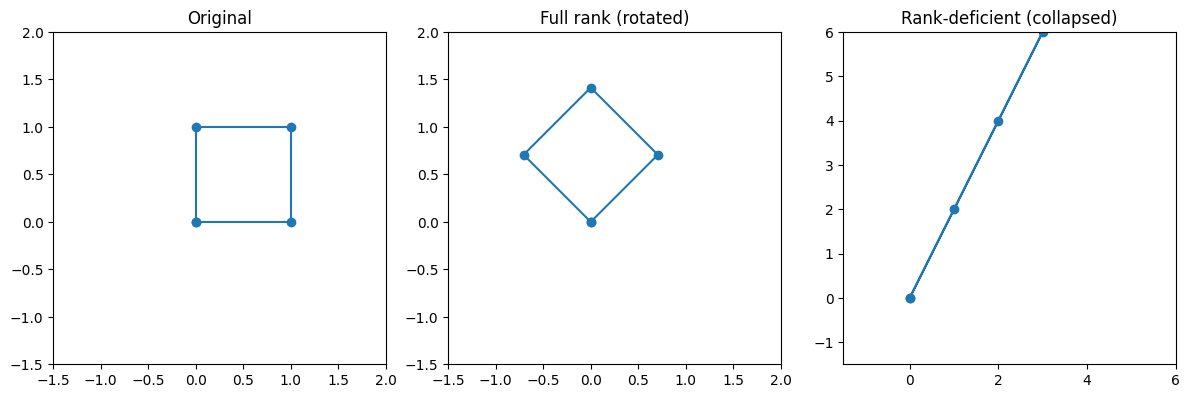

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ["Original", "Full rank (rotated)", "Rank-deficient (collapsed)"]
data = [square, rotated, collapsed]
lims = [(-1.5, 2), (-1.5, 2), (-1.5, 6)]

for ax, title, pts, lim in zip(axes, titles, data, lims):
    ax.plot(pts[0], pts[1], marker="o")
    ax.set_title(title)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()


**What just happened:** The rotation preserves the square's shape entirely - full rank
means no information is lost, just repositioned. The rank-deficient matrix, though, maps
every point in the square onto a single line: an entire 2-dimensional shape gets
flattened into 1 dimension. That flattening is *exactly* what "rank-deficient" means in
practice, not just in a formula - and it's not reversible by multiplying by anything else.


### Rank isn't about being square

18% of diagnostic responses thought "rank-deficient" meant "not a square matrix." A
quick, direct check of that idea.


In [ ]:
non_square = np.array([[1, 0, 1],
                        [0, 1, 1]])  # 2x3, not square
print("A 2x3 matrix (not square). Rank:", np.linalg.matrix_rank(non_square))
print("Full rank, despite not being square -- shape was never the test, independence always was.")


A 2x3 matrix (not square). Rank: 2
Full rank, despite not being square -- shape was never the test, independence always was.


## Try it yourself

**Try:** replace `rank_deficient` with your own 2x2 matrix. Pick one where the second
row/column is *not* a multiple of the first, check that `np.linalg.matrix_rank(...)`
now reports 2, and confirm the plotted shape no longer collapses to a line.


In [ ]:
# my_matrix = np.array([[?, ?], [?, ?]])
# print("Rank:", np.linalg.matrix_rank(my_matrix))


### In Action — Rank and Redundant Columns in Real Data

Real datasets often contain a column that's mostly redundant with others — a
"composite score," a derived ratio, a total that's just a sum of columns already in
the table. Rank is the tool that catches this automatically.


In [ ]:
cols = iris[["sepal length (cm)", "sepal width (cm)", "petal length (cm)"]].values
print("Rank of the original 3-column matrix:", np.linalg.matrix_rank(cols))

# Add a column that's just a linear combination of the others - the kind of derived
# "composite score" column that sneaks into real datasets without anyone noticing
composite = (0.5 * iris["sepal length (cm)"].values
             + 2 * iris["sepal width (cm)"].values
             - 3 * iris["petal length (cm)"].values)
cols_redundant = np.column_stack([cols, composite])

print("Rank after adding the composite column:", np.linalg.matrix_rank(cols_redundant))
print(f"Still {np.linalg.matrix_rank(cols)} - a 4th column, but zero new information.")


Rank of the original 3-column matrix: 3
Rank after adding the composite column: 3
Still 3 - a 4th column, but zero new information.


**What just happened:** the composite column added a whole new column of numbers to
the table, but not a new *dimension* of information — rank caught that immediately.
This is the real-data version of "rank-deficient": in practice it's called
**multicollinearity**, and it's exactly the problem Module 7's regularization
(Ridge/Lasso) exists to handle.


## Part 3 — Orthogonal projection: closest point on a line, and checking your work

Given a vector `b` and a direction `a`, the projection of `b` onto `a` is the closest
point to `b` that lies *on* the line through `a`. The residual (what's left over) should
always be orthogonal to `a` - that's not a coincidence, it's the definition of "closest,"
and it's the single check that catches almost every projection mistake.


In [ ]:
a = np.array([3, 1])
b = np.array([2, 4])

# proj_a(b) = (a.b / a.a) * a
scalar = np.dot(a, b) / np.dot(a, a)
projection = scalar * a
residual = b - projection

print("Projection of b onto a:", projection)
print("Residual (b - projection):", residual)
print("Orthogonality check - residual . a =", np.dot(residual, a), "(should be ~0)")


Projection of b onto a: [3. 1.]
Residual (b - projection): [-1.  3.]
Orthogonality check - residual . a = 0.0 (should be ~0)


**What just happened:** The dot product of the residual and `a` comes out to (numerically)
zero, confirming the residual really is perpendicular to `a` - which is exactly what makes
the projection the *closest* point on the line, not just some point on it. This is the
same mechanism Module 4 uses for least squares, just extended from a line to a full subspace.


## Try it yourself

**Try:** change `a` and `b` to your own vectors and re-run. Then try a `b` that already
lies exactly on the line through `a` (e.g. `b = 2 * a`) - what happens to the residual?


In [ ]:
# a = np.array([?, ?])
# b = np.array([?, ?])
# re-run the projection cell above with your new values


### In Action — Seeing a Real Projection

Same projection idea as above, but built from two real iris measurements and
plotted, so the geometry - not just the numbers - is visible. `a` is a real,
data-derived direction (the difference between two species' average petal shape);
`b` is a real flower from a third species.


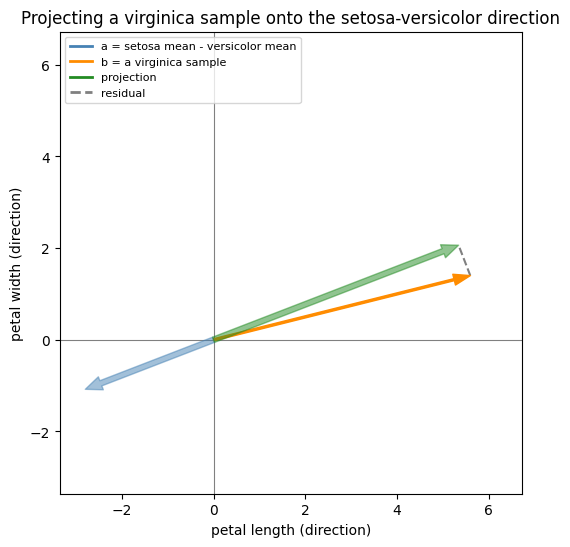

Orthogonality check - residual . a = 1.5543122344752192e-15


In [ ]:
feat2 = iris[["petal length (cm)", "petal width (cm)"]]
mean_setosa = feat2[iris["target"] == 0].mean()
mean_versicolor = feat2[iris["target"] == 1].mean()
a2 = (mean_setosa - mean_versicolor).values

# row 134: a virginica sample whose petal shape doesn't fit the setosa-versicolor
# pattern as well as most -- gives a residual worth actually seeing on the plot
b2 = feat2.loc[134].values

scalar2 = np.dot(a2, b2) / np.dot(a2, a2)
projection2 = scalar2 * a2
residual2 = b2 - projection2

pts = np.vstack([a2, b2, projection2, [0, 0]])
lo, hi = pts.min() * 1.2, pts.max() * 1.2

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
ax.annotate("", xy=b2, xytext=(0, 0), arrowprops=dict(color="darkorange", width=1.5, headwidth=8))
# a and projection are always exactly collinear (projection = scalar * a) -- that's
# what "projection" means. Here scalar is negative, so they happen to point in
# opposite directions and land in different quadrants -- but a semi-transparent
# color is used anyway, so this stays correct even if you change the data (in
# "Try it yourself" below) to a case where they do overlap.
ax.annotate("", xy=a2, xytext=(0, 0), arrowprops=dict(color=mcolors.to_rgba("steelblue", 0.5), width=4, headwidth=10))
ax.annotate("", xy=projection2, xytext=(0, 0), arrowprops=dict(color=mcolors.to_rgba("forestgreen", 0.5), width=4, headwidth=10))
ax.plot([b2[0], projection2[0]], [b2[1], projection2[1]], "--", color="grey")
ax.set_xlabel("petal length (direction)")
ax.set_ylabel("petal width (direction)")
ax.set_title("Projecting a virginica sample onto the setosa-versicolor direction")
legend_handles = [
    plt.Line2D([0], [0], color="steelblue", lw=2, label="a = setosa mean - versicolor mean"),
    plt.Line2D([0], [0], color="darkorange", lw=2, label="b = a virginica sample"),
    plt.Line2D([0], [0], color="forestgreen", lw=2, label="projection"),
    plt.Line2D([0], [0], color="grey", lw=2, linestyle="--", label="residual"),
]
ax.legend(handles=legend_handles, loc="upper left", fontsize=8)
ax.set_aspect("equal")
plt.show()

print("Orthogonality check - residual . a =", np.dot(residual2, a2))


**What just happened:** the green arrow is the closest "a-direction" approximation of
this virginica sample's actual position; the grey dashed segment is the leftover,
orthogonal error - the residual. This exact picture, generalized from 2 dimensions to
many, is what least squares regression does in Module 4: find the best approximation
*within a subspace*, and leave the unexplained part as an orthogonal residual.

**Notice the overlap (or lack of it):** `a` and `projection` are always exactly
collinear - here the scalar is negative, so they point opposite directions and don't
visually overlap. Try picking a different virginica row (or a different pair of
species means) in the code above - you may land on a case where `scalar` is positive
and the two arrows do overlap. The semi-transparent color is there for exactly that
case, so the plot stays readable either way.


## Wrap-up

**Key takeaway:** vectors, norms, and rank all answer "how much information is really
here, and how do we measure it" - and orthogonal projection answers "what's the closest
match, given a direction (or subspace) to work with."

**Connects to:** Module 3 (SVD/PCA - rank and "effective complexity" done properly) and
Module 4 (systems and projections - this notebook's Part 3, extended to least squares).

**Suggested reading:** *Mathematics for Machine Learning* (mml-book.com) §2.6 Basis and
Rank, and §3.8 Orthogonal Projections, are the most direct matches for Parts 2 and 3 of
this notebook. *Introduction to Applied Linear Algebra* (VMLS, web.stanford.edu/~boyd/vmls)
Ch. 5 covers the same independence/orthonormal-vectors ground with a more computational style.

**The In Action sections**, if anything stuck: un-scaled real features can silently
dominate a norm, a "composite" column can silently cost you nothing in rank, and a
projection is a genuinely visible geometric fact, not just an algebra exercise.

Questions? Post in the course forum/chat - the peer TA and I both check it regularly.
